# Рабочая тетрадь №7 часть 1

In [284]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import confusion_matrix
from sklearn.neural_network import MLPRegressor

### 1.1.3 Задание 

Реализовать классы нейросетей по аналогии с классом OurNeuralNetwork.

Данные нейросети:
- три входа (𝑥1, 𝑥2, 𝑥3);
- три нейрона в скрытых слоях (ℎ1, ℎ2, ℎ3);
- выход (𝑜1).

Нейроны имеют идентичные веса и пороги:
- 𝑤 = [0.5, 0.5, 0.5]
- 𝑏 = 0

Данные нейросети:
- два входа (𝑥1, 𝑥2);
- два нейрона в скрытых слоях (ℎ1, ℎ2);
- два выхода (𝑜1, 𝑜2).

Нейроны имеют идентичные веса и пороги:
- 𝑤 = [1, 0];
- 𝑏 = 1.

In [285]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))


def tanh(x):
    return np.tan(x)


def ReLU(x):
    return max(0, x)

In [286]:
class Neuron:
    def __init__(self, weights, bias):
        self.weights = weights
        self.bias = bias
    
    def feedforwardSigmoid(self, inputs):
        total = np.dot(self.weights, inputs) + self.bias
        return sigmoid(total)
    
    def feedforwardTanh(self, inputs):
        total = np.dot(self.weights, inputs) + self.bias
        return tanh(total)
    
    def feedforwardReLU(self, inputs):
        total = np.dot(self.weights, inputs) + self.bias
        return ReLU(total)

In [287]:
class OurNeuralNetwork1:
    def __init__(self):
        weights = np.array([0.5, 0.5, 0.5])
        bias = 0
        self.h1 = Neuron(weights, bias)
        self.h2 = Neuron(weights, bias)
        self.h3 = Neuron(weights, bias)
        self.o1 = Neuron(weights, bias)
    
    def feedforward_1(self, x):
        out_h1 = self.h1.feedforwardSigmoid(x)
        out_h2 = self.h2.feedforwardSigmoid(x)
        out_h3 = self.h3.feedforwardSigmoid(x)
        out_o1 = self.o1.feedforwardSigmoid(np.array([out_h1, out_h2, out_h3]))
        return out_o1
    
    def feedforward_2(self, x):
        out_h1 = self.h1.feedforwardTanh(x)
        out_h2 = self.h2.feedforwardTanh(x)
        out_h3 = self.h3.feedforwardTanh(x)
        out_o1 = self.o1.feedforwardTanh(np.array([out_h1, out_h2, out_h3]))
        return out_o1
    
    def feedforward_3(self, x):
        out_h1 = self.h1.feedforwardReLU(x)
        out_h2 = self.h2.feedforwardReLU(x)
        out_h3 = self.h3.feedforwardReLU(x)
        out_o1 = self.o1.feedforwardReLU(np.array([out_h1, out_h2, out_h3]))
        return out_o1

In [288]:
class OurNeuralNetwork2:
    def __init__(self):
        weights = np.array([1, 0])
        bias = 1
        self.h1 = Neuron(weights, bias)
        self.h2 = Neuron(weights, bias)
        self.o1 = Neuron(weights, bias)
        self.o2 = Neuron(weights, bias)
    
    def feedforward_1(self, x):
        out_h1 = self.h1.feedforwardSigmoid(x)
        out_h2 = self.h2.feedforwardSigmoid(x)
        out_o1 = self.o1.feedforwardSigmoid(np.array([out_h1, out_h2]))
        out_o2 = self.o2.feedforwardSigmoid(np.array([out_h1, out_h2]))
        return out_o1, out_o2
    
    def feedforward_2(self, x):
        out_h1 = self.h1.feedforwardTanh(x)
        out_h2 = self.h2.feedforwardTanh(x)
        out_o1 = self.o1.feedforwardTanh(np.array([out_h1, out_h2]))
        out_o2 = self.o2.feedforwardTanh(np.array([out_h1, out_h2]))
        return out_o1, out_o2
    
    def feedforward_3(self, x):
        out_h1 = self.h1.feedforwardReLU(x)
        out_h2 = self.h2.feedforwardReLU(x)
        out_o1 = self.o1.feedforwardReLU(np.array([out_h1, out_h2]))
        out_o2 = self.o2.feedforwardReLU(np.array([out_h1, out_h2]))
        return out_o1, out_o2

In [289]:
network1 = OurNeuralNetwork1()
x1 = np.array([1, 2, 3])

print("Сигмоид нейронной сети:", network1.feedforward_1(x1))
print("Тангенс нейронной сети:", network1.feedforward_2(x1))
print("ReLU нейронной сети:", network1.feedforward_3(x1))

Сигмоид нейронной сети: 0.8067238139969796
Тангенс нейронной сети: -0.2171390653776728
ReLU нейронной сети: 4.5


In [290]:
network2 = OurNeuralNetwork2()
x2 = np.array([2, 3])

print("Сигмоид нейронной сети:", network2.feedforward_1(x2))
print("Тангенс нейронной сети:", network2.feedforward_2(x2))
print("ReLU нейронной сети:", network2.feedforward_3(x2))

Сигмоид нейронной сети: (0.8757270529783324, 0.8757270529783324)
Тангенс нейронной сети: (1.1555911185916796, 1.1555911185916796)
ReLU нейронной сети: (4, 4)


### 1.2 Задание 

Используйте классы MLPClassified и MLPRegressor для классификации и регрессии произвольных данных из интернета. Проведите анализ атрибуты, полученных моделей.

Для классификации можете взять набор данных Ирисов:

https://gist.githubusercontent.com/netj/8836201/raw/6f9306ad21398ea43cba4f7d537619d0e07d5ae3/iris.csv

а для регрессии датасет зависимости заработной платы от опыта работы:

https://raw.githubusercontent.com/AnnaShestova/salary-years-simple-linear-regression/master/Salary_Data.csv

In [291]:
url = "https://raw.githubusercontent.com/AnnaShestova/salary-years-simple-linear-regression/master/Salary_Data.csv"

ds = pd.read_csv(url)

ds.describe()

,YearsExperience,Salary
count,30.000000,30.000000
mean,5.313333,76003.000000
std,2.837888,27414.429785
min,1.100000,37731.000000
25%,3.200000,56720.750000
50%,4.700000,65237.000000
75%,7.700000,100544.750000
max,10.500000,122391.000000


In [292]:
X = ds.iloc[:, :-1].values 
Y = ds.iloc[:, 1].values

print("Dataset Sizes:", X.shape, Y.shape)

Dataset Sizes: (30, 1) (30,)


In [293]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, train_size=0.80, test_size=0.20, random_state=123)

print('Train/Test Sizes:', X_train.shape, X_test.shape, Y_train.shape, Y_test.shape)

Train/Test Sizes: (24, 1) (6, 1) (24,) (6,)


In [294]:
mlp_classifier = MLPClassifier(random_state=123, max_iter=50000)
mlp_classifier.fit(X_train, Y_train)

Y_preds = mlp_classifier.predict(X_test)

In [295]:
print(Y_preds[:15]) 
print(Y_test[:15]) 
print('Test Accuracy : %.3f'%mlp_classifier.score(X_test, Y_test))
print('Training Accuracy : %.3f'%mlp_classifier.score(X_train, Y_train))

[ 60150. 122391.  60150. 105582.  60150. 105582.]
[ 54445. 121872.  56642. 116969.  64445. 112635.]
Test Accuracy : 0.000
Training Accuracy : 0.958


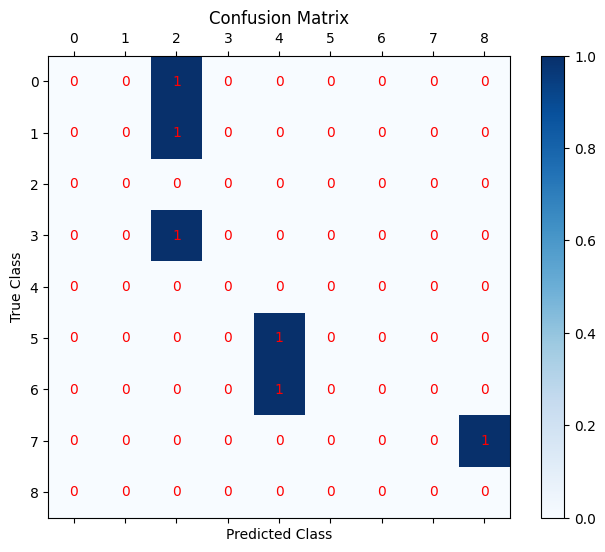

In [296]:
classes = np.arange(9)
cm = confusion_matrix(Y_test, Y_preds)

fig, ax = plt.subplots(figsize=(8, 6))

cax = ax.matshow(cm, cmap='Blues')
plt.colorbar(cax)

ax.set_xticks(np.arange(len(classes)))
ax.set_yticks(np.arange(len(classes)))
ax.set_xticklabels(classes)
ax.set_yticklabels(classes)

plt.xlabel('Predicted Class')
plt.ylabel('True Class')
plt.title('Confusion Matrix')
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(x=j, y=i, s=cm[i, j], va='center', ha='center', color="red")
plt.show()

In [297]:
print("Loss: ", mlp_classifier.loss_) 
print("Number of Coefs: ", len(mlp_classifier.coefs_)) 
print("Number of Intercepts: ", len(mlp_classifier.intercepts_)) 
print("Number of Iterations for Which Estimator Ran: ", mlp_classifier.n_iter_) 
print("Name of Output Layer Activation Function: ",mlp_classifier.out_activation_)

Loss:  0.3026602459630493
Number of Coefs:  2
Number of Intercepts:  2
Number of Iterations for Which Estimator Ran:  6194
Name of Output Layer Activation Function:  softmax


---

In [298]:
mlp_regressor = MLPRegressor(random_state=123, max_iter=50000) 
mlp_regressor.fit(X_train, Y_train)

Y_preds = mlp_regressor.predict(X_test)

In [299]:
print(Y_preds[:10]) 
print(Y_test[:10]) 
print(f"Test R^2 Score: {mlp_regressor.score(X_test, Y_test):.3f}") 
print(f"Training R^2 Score: {mlp_regressor.score(X_train, Y_train):.3f}")

[ 55265.2045971  126554.5591937   52335.80522199 116782.59147446
  55265.2045971  117759.05793283]
[ 54445. 121872.  56642. 116969.  64445. 112635.]
Test R^2 Score: 0.971
Training R^2 Score: 0.948


In [300]:
print("Loss:", mlp_regressor.loss_)
print("Number of Coefs:", len(mlp_regressor.coefs_)) 
print("Number of Iterations for Which Estimator Ran:", mlp_regressor.n_iter_)
print("Name of Output Layer Activation Function:", mlp_regressor.out_activation_)

Loss: 16873681.689960096
Number of Coefs: 2
Number of Iterations for Which Estimator Ran: 30344
Name of Output Layer Activation Function: identity
